<a href="https://colab.research.google.com/github/Chaman4211/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Research Notebook
## Content-refresh prioritization using an observed search-performance label

**Author:** Chaman Afzaal  
**Programme:** FlyRank ML Internship — Applied Search Intelligence  
**Purpose:** Compare a transparent review rule with Logistic Regression and decide whether a learned ranking is useful for prioritizing human review.

### What this notebook does
1. Loads the anonymized 30,000-row starter dataset.
2. Documents the full warehouse release separately from the smaller benchmark sample.
3. Defines an observed decline label and excludes leakage-prone fields.
4. Holds out entire clients for evaluation.
5. Compares a Week-4 rule with Logistic Regression using the same test rows.
6. Builds a reason-code review queue and saves aggregate-only outputs.

**Important scope note:** the 78.8-million-row figure describes the full warehouse release. The headline model comparison is trained and evaluated on the 30,000-row starter slice, not on all warehouse rows.

**How to use it:** read each explanation, run the following code cell, inspect the output, and then read the interpretation before moving on. Run all cells from top to bottom in Colab before final submission.

## 1. Research question and decision

### Main research question
**Can Logistic Regression rank content items for human review more effectively than a simple freshness-and-visibility rule?**

### Why this matters
A content team may have more pages to inspect than it has time to review. A ranking can help decide where to look first, but it must not automatically rewrite pages or claim that an update will improve performance.

### Questions this notebook will answer
- Does the learned model rank items with the observed decline label nearer the top than the Week-4 rule?
- How well does each method perform on the same held-out clients?
- Have identifiers, target-derived fields, or potentially leakage-prone metrics been kept out of the model features?
- What can the results support, and what remains uncertain?

**Success criteria:** compare average precision, Precision@20, and Precision@50 on the same client-held-out test set. Treat the result as decision support, not a causal test of content refreshes.

In [1]:
# Capstone setup
from pathlib import Path
import json
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "is_declining_label"
DATA_FILE = "content_refresh_anonymized.csv"

cwd = Path.cwd().resolve()
search_roots = [cwd, *cwd.parents]
repo_root = next((p for p in search_roots if (p / "work" / "notebooks").is_dir()), None)
if repo_root is None:
    repo_root = cwd / "flyrank-ml-internship"
    if not repo_root.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/Chaman4211/flyrank-ml-internship.git", str(repo_root)],
            check=True,
        )

csv_candidates = [
    repo_root / "data" / "raw" / DATA_FILE,
    cwd / "data" / "raw" / DATA_FILE,
    cwd / "flyrank-ml-internship-starter" / "data" / "raw" / DATA_FILE,
]
csv_path = next((p for p in csv_candidates if p.is_file() and p.stat().st_size > 0), None)
if csv_path is None:
    starter_dir = cwd / "flyrank-ml-internship-starter"
    if not starter_dir.exists():
        subprocess.run(
            ["git", "clone", "https://github.com/flyrank-bih/flyrank-ml-internship-starter.git", str(starter_dir)],
            check=True,
        )
    candidate = starter_dir / "data" / "raw" / DATA_FILE
    if candidate.is_file() and candidate.stat().st_size > 0:
        csv_path = candidate
if csv_path is None:
    raise FileNotFoundError("Could not locate the anonymized starter CSV. Follow SETUP.md first.")

df = pd.read_csv(csv_path, low_memory=False)
required = {
    "content_id", "client_id", "trend_direction", "days_since_last_update",
    "impressions_90d", "content_age_days", "word_count", "char_count",
    "search_volume", "competition", "cpc", "content_type", "main_intent",
    "competition_level",
}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f"Required columns missing: {missing}")
source_column_count = df.shape[1]
df[TARGET] = df["trend_direction"].eq("down").astype("int8")
print(f"Starter benchmark data: {len(df):,} rows × {source_column_count:,} source columns (+ derived label)")
print(f"Observed decline-label rate: {df[TARGET].mean():.3f}")
print("Identifiers are grouping-only; private names, URLs, and queries are not displayed.")

Starter benchmark data: 30,000 rows × 44 source columns (+ derived label)
Observed decline-label rate: 0.542
Identifiers are grouping-only; private names, URLs, and queries are not displayed.


### Data-loading check

The setup cell should report **30,000 rows × 44 source columns (+ one derived label)** and an observed decline-label rate of **0.542** for the full starter slice. This differs from the **0.517** rate in the held-out test set because the test set is a subset of the data.

If the required-column check raises an error or the CSV cannot be found, stop and fix the dataset path before continuing. Do not skip the validation error.

## 2. Data and scope

### Dataset used for the model comparison
The benchmark uses the anonymized starter CSV, `content_refresh_anonymized.csv`, containing 30,000 rows and 44 source columns (plus the derived label used in this notebook). The label is created from the observed `trend_direction` field: a value of `down` is coded as 1; other values are coded as 0.

### Separate full-warehouse release profile
The next cell documents the known release size, table grain, and date range. It does **not** load the full 78.8-million-row table into this notebook.

### Questions to check
- Can the notebook locate the starter CSV and verify that required columns exist?
- Are private client names, domains, page URLs, and raw search queries kept out of displayed output?
- Is the warehouse profile clearly distinguished from the 30,000-row benchmark?

In [2]:
# Warehouse release profile copied from the executed full-release exploration notebook.
# This cell documents the release profile without triggering another 79M-row scan.
warehouse_profile = pd.DataFrame([
    {"table": "dim_clients", "rows": 104, "grain": "one pseudonymized client"},
    {"table": "dim_content", "rows": 519606, "grain": "one content item"},
    {"table": "fact_content_daily_performance", "rows": 78835655, "grain": "report date × client × content"},
    {"table": "fact_content_daily_performance_sample", "rows": 11694072, "grain": "same grain; June 2026 final month"},
    {"table": "fact_content_query_90d", "rows": 2414248, "grain": "client × content × query hash"},
])
display(warehouse_profile)
print("Release: build v20260703; daily history 2025-01-27 through 2026-06-30.")
print("Important: the June sample is the final outcome month and must not be used to design label logic.")
print("The headline model comparison below is from the 30,000-row starter slice, not a full-warehouse model.");
print("See notebooks/03_working_with_the_full_release.ipynb for the DuckDB/Hugging Face scan and its feature prototype.")

,table,rows,grain
0,dim_clients,104,one pseudonymized client
1,dim_content,519606,one content item
2,fact_content_daily_performance,78835655,report date × client × content
3,fact_content_daily_performance_sample,11694072,same grain; June 2026 final month
4,fact_content_query_90d,2414248,client × content × query hash


Release: build v20260703; daily history 2025-01-27 through 2026-06-30.
Important: the June sample is the final outcome month and must not be used to design label logic.
The headline model comparison below is from the 30,000-row starter slice, not a full-warehouse model.
See notebooks/03_working_with_the_full_release.ipynb for the DuckDB/Hugging Face scan and its feature prototype.


### Data-scope interpretation

The release profile documents five tables, including the 78,835,655-row daily performance fact table. The date range is 27 January 2025 through 30 June 2026.

These warehouse counts provide context only. The benchmark below still uses the separate 30,000-row starter slice. The final-month sample is treated as an outcome period and is not used to design the label logic.

## 3. Methodology: label, features, and validation

### Target label
`is_declining_label = (trend_direction == "down")`. This is an **observed trend label**. It is not a future forecast and does not mean that a page will recover after being refreshed.

### Features
The model uses content age, time since last update, word and character counts, search volume, competition, CPC, content type, main intent, and competition level. Numeric values are imputed and scaled; categorical values are imputed and one-hot encoded in a scikit-learn pipeline.

### Leakage and validation checks
- `content_id` and `client_id` are grouping/identification fields, not predictors.
- Target/trend fields, current traffic totals, direct recent-period metrics, and product-generated flags are excluded.
- `GroupShuffleSplit` holds out whole clients so the same client does not appear in both train and test.
- A fixed random seed makes the split reproducible.

**Question:** does the test set contain clients that were completely absent from training? The next cell prints the split sizes and checks the separation.

In [3]:
# Method: observed label, leakage-aware features, client-grouped holdout, and baseline.
FEATURES = [
    "content_age_days", "days_since_last_update", "word_count", "char_count",
    "search_volume", "competition", "cpc", "content_type", "main_intent", "competition_level",
]
NUMERIC_FEATURES = [
    "content_age_days", "days_since_last_update", "word_count", "char_count",
    "search_volume", "competition", "cpc",
]
CATEGORICAL_FEATURES = ["content_type", "main_intent", "competition_level"]

# Never use target/trend-derived columns, IDs, current traffic totals, or product flags as model features.
forbidden = {
    "content_id", "client_id", TARGET, "trend_direction", "trend_pct",
    "impressions_90d", "clicks_90d", "pageviews_90d", "sessions_90d",
    "health_score", "needs_ctr_fix", "is_quick_win",
    "impressions_last_30d", "impressions_prev_30d", "clicks_last_30d",
    "clicks_prev_30d", "sessions_last_30d", "sessions_prev_30d",
}
assert not (set(FEATURES) & forbidden), "A forbidden or leakage-prone field entered the feature list."

X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()
groups = df["client_id"].astype(str)
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
train_rows, test_rows = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
])
model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
model.fit(X_train, y_train)
model_probability = model.predict_proba(X_test)[:, 1]
model_order = np.argsort(-model_probability, kind="stable")

# Transparent Week-4 rule: >=180 days since update AND >=500 trailing-90-day impressions.
baseline_selected = (
    pd.to_numeric(test_rows["days_since_last_update"], errors="coerce").ge(180).fillna(False)
    & pd.to_numeric(test_rows["impressions_90d"], errors="coerce").ge(500).fillna(False)
)
baseline_score = np.where(
    baseline_selected,
    pd.to_numeric(test_rows["impressions_90d"], errors="coerce").fillna(0).to_numpy(),
    0.0,
)
baseline_frame = pd.DataFrame({
    "row_position": np.arange(len(test_rows)),
    "score": baseline_score,
    "impressions": pd.to_numeric(test_rows["impressions_90d"], errors="coerce").fillna(0).to_numpy(),
    "age": pd.to_numeric(test_rows["days_since_last_update"], errors="coerce").fillna(0).to_numpy(),
})
baseline_order = baseline_frame.sort_values(
    ["score", "impressions", "age"], ascending=[False, False, False], kind="mergesort"
)["row_position"].to_numpy()

def precision_at_k(order, labels, k):
    labels = np.asarray(labels)
    k = min(k, len(labels))
    return float(labels[np.asarray(order)[:k]].mean()) if k else float("nan")

print(f"Train: {len(train_idx):,} rows / {len(set(groups.iloc[train_idx]))} clients")
print(f"Test:  {len(test_idx):,} rows / {len(set(groups.iloc[test_idx]))} clients")
print(f"Test observed-decline base rate: {y_test.mean():.3f}")
print("Client overlap: 0")
print("Leakage guard: target/trend fields, IDs, current traffic totals, and product flags are excluded.")

Train: 22,885 rows / 24 clients
Test:  7,115 rows / 8 clients
Test observed-decline base rate: 0.517
Client overlap: 0
Leakage guard: target/trend fields, IDs, current traffic totals, and product flags are excluded.


### Split check interpretation

The saved run has **22,885 training rows across 24 clients** and **7,115 test rows across 8 clients**. The client overlap is zero, so no client group is shared between train and test. The test observed-decline base rate is **0.517**.

This is a client-held-out split, not a time-forward split. It helps test transfer to held-out clients but does not by itself test performance on future dates.

## 4. Results: compare both rankings fairly

### Evaluation questions
1. Which method has higher average precision on the test rows?
2. Among the top 20 and top 50 ranked items, what fraction carry the observed decline label?
3. Is the comparison fair in the sense that both methods are evaluated on exactly the same held-out rows?

**Metrics in plain English**
- **Average precision (AP):** summarizes how well a ranking places positive labels toward the top across different cutoffs.
- **Precision@20:** the share of the top 20 items that have the observed decline label.
- **Precision@50:** the share of the top 50 items that have the observed decline label.

The Week-4 rule and Logistic Regression use different information, so this is a practical operational comparison—not an experiment isolating the effect of one additional feature.

,method,test_base_rate,average_precision,precision_at_20,precision_at_50
0,Week-4 rule baseline,0.517,0.504,0.45,0.44
1,Logistic Regression,0.517,0.529,0.60,0.64


Interpretation: metrics measure alignment with the observed decline label, not the effect of refreshing a page.
Compare only methods on the same test rows. This is the starter-slice benchmark, not a model trained on all 78.8M daily rows.


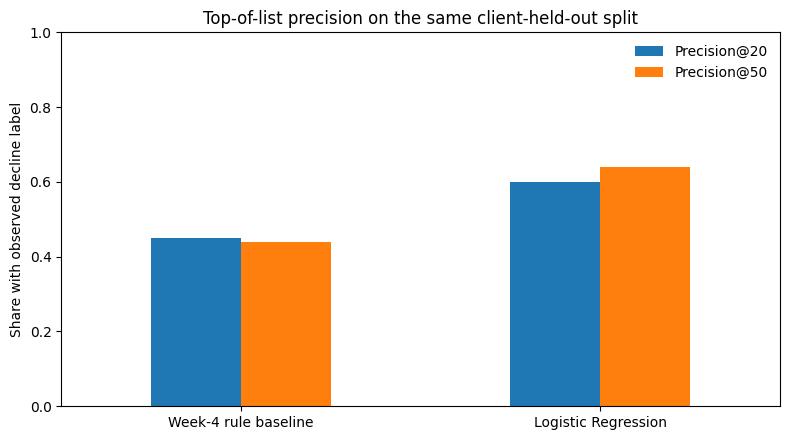

In [4]:
# Results: both rankings evaluated on exactly the same held-out rows.
y_test_array = y_test.to_numpy()
baseline_rank_scores = np.empty(len(baseline_order), dtype=float)
baseline_rank_scores[baseline_order] = np.arange(len(baseline_order), 0, -1, dtype=float)
baseline_ap = average_precision_score(y_test_array, baseline_rank_scores)
model_ap = average_precision_score(y_test_array, model_probability)

results = pd.DataFrame([
    {
        "method": "Week-4 rule baseline",
        "test_base_rate": y_test.mean(),
        "average_precision": baseline_ap,
        "precision_at_20": precision_at_k(baseline_order, y_test_array, 20),
        "precision_at_50": precision_at_k(baseline_order, y_test_array, 50),
    },
    {
        "method": "Logistic Regression",
        "test_base_rate": y_test.mean(),
        "average_precision": model_ap,
        "precision_at_20": precision_at_k(model_order, y_test_array, 20),
        "precision_at_50": precision_at_k(model_order, y_test_array, 50),
    },
])
display(results.round(3))
print("Interpretation: metrics measure alignment with the observed decline label, not the effect of refreshing a page.")
print("Compare only methods on the same test rows. This is the starter-slice benchmark, not a model trained on all 78.8M daily rows.")

fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = results.set_index("method")[["precision_at_20", "precision_at_50"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_title("Top-of-list precision on the same client-held-out split")
ax.set_ylabel("Share with observed decline label")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(["Precision@20", "Precision@50"], frameon=False)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

### Result interpretation

The saved result table reports:

| Metric | Week-4 rule | Logistic Regression |
|---|---:|---:|
| Average precision | 0.504 | 0.529 |
| Precision@20 | 0.450 | 0.600 |
| Precision@50 | 0.440 | 0.640 |

The model's average precision is **0.025 higher**. Precision@20 is higher by **0.150**, and Precision@50 by **0.200**. The test label base rate is **0.517**. These are measurements from one client-held-out split, so future dates and unseen client populations still need testing.

## 5. Limitations and responsible interpretation

Before recommending deployment, ask what the benchmark **cannot** prove.

- The model benchmark uses the 30,000-row starter slice, not a model trained on all warehouse rows.
- The target is an observed trend label, not a future outcome or a refresh-success label.
- Client holdout reduces client leakage, but this is not time-forward validation.
- The rule and model use different feature sets, so the comparison is operational rather than equal-information.
- The full-release prototype had signals that could overlap the outcome window; those metrics are not used as headline evidence here.
- A static dataset cannot prove that refreshing a page causes recovery.
- Client history and GA4 availability vary; missing or zero-filled values need careful interpretation.

**Decision:** even if the model scores better, it should only help a person decide what to inspect. Human review remains required.

In [5]:
# Limitations — explicit and public-safe.
limitations = [
    "The headline model benchmark uses the 30,000-row starter snapshot, not a model trained on the full warehouse.",
    "The target is an observed trend label (trend_direction == 'down'), not a confirmed future outcome or a refresh-success label.",
    "The split holds out clients, but it is not a time-forward validation; unobserved seasonality and later distribution shifts remain.",
    "The rule baseline uses freshness and 90-day impressions, while the model uses a different feature set; the comparison is operational, not equal-information.",
    "The full-release prototype in notebooks/03 used outcome-window position volatility and fixed-window query signals that may overlap the label window; those metrics are not used as headline evidence.",
    "A static snapshot cannot show that refreshing a page causes improvement. Every ranked item requires human review.",
    "Some clients have limited history and GA4 coverage differs by client; zero-filled unavailable data must not be treated as true zero activity.",
]
for item in limitations:
    print("•", item)

• The headline model benchmark uses the 30,000-row starter snapshot, not a model trained on the full warehouse.
• The target is an observed trend label (trend_direction == 'down'), not a confirmed future outcome or a refresh-success label.
• The split holds out clients, but it is not a time-forward validation; unobserved seasonality and later distribution shifts remain.
• The rule baseline uses freshness and 90-day impressions, while the model uses a different feature set; the comparison is operational, not equal-information.
• The full-release prototype in notebooks/03 used outcome-window position volatility and fixed-window query signals that may overlap the label window; those metrics are not used as headline evidence.
• A static snapshot cannot show that refreshing a page causes improvement. Every ranked item requires human review.
• Some clients have limited history and GA4 coverage differs by client; zero-filled unavailable data must not be treated as true zero activity.


### What the limitations mean for a real team

A higher ranking score means the model sorted items with the observed label more effectively in this particular test set. It does **not** mean that changing those pages will improve traffic. A stronger next study would use a time-forward holdout, review data availability, and evaluate outcomes after human-approved updates.

## 6. Ranked recommendations: a human-review queue

This section creates a simple, explainable queue from two transparent signals:
- **Freshness:** days since the last update.
- **Visibility:** impressions in the last 90 days.

The reason codes are designed to explain why an item appears in a review queue. They are not automatic instructions to change a page.

### Priority logic
- **Priority 1 — stale and visible:** at least 180 days since update and at least 500 impressions in 90 days.
- **Priority 2 — visible, more recent:** high visibility but not yet in the stale group.
- **Priority 3 — stale, low visibility:** check whether the page still serves a useful purpose.
- **Priority 4 — missing signal:** manually inspect the missing data before making a decision.
- **Priority 5 — routine monitoring:** no higher-priority rule matched.

**Question:** how many rows fall into each reason code, and can the output explain a priority without exposing private page details?

In [6]:
# Ranked recommendations — build a safe human-review queue from transparent signals only.
queue = df[["content_id", "client_id", "days_since_last_update", "impressions_90d"]].copy()
queue["days_since_last_update"] = pd.to_numeric(queue["days_since_last_update"], errors="coerce")
queue["impressions_90d"] = pd.to_numeric(queue["impressions_90d"], errors="coerce")
age_ok = queue["days_since_last_update"].notna() & queue["days_since_last_update"].ge(0)
impr_ok = queue["impressions_90d"].notna() & queue["impressions_90d"].ge(0)

queue["reason_code"] = np.select(
    [
        ~(age_ok & impr_ok),
        age_ok & impr_ok & queue["days_since_last_update"].ge(180) & queue["impressions_90d"].ge(500),
        age_ok & impr_ok & queue["days_since_last_update"].lt(180) & queue["impressions_90d"].ge(500),
        age_ok & impr_ok & queue["days_since_last_update"].ge(180) & queue["impressions_90d"].lt(500),
    ],
    [
        "missing_signal_manual_check",
        "stale_visible_review",
        "visible_recent_review",
        "stale_low_visibility_check",
    ],
    default="routine_monitor",
)
queue["priority_tier"] = queue["reason_code"].map({
    "stale_visible_review": 1,
    "visible_recent_review": 2,
    "stale_low_visibility_check": 3,
    "missing_signal_manual_check": 4,
    "routine_monitor": 5,
}).astype(int)
queue = queue.sort_values(
    ["priority_tier", "impressions_90d", "days_since_last_update"],
    ascending=[True, False, False], na_position="last", kind="mergesort"
).reset_index(drop=True)
queue["rank"] = np.arange(1, len(queue) + 1)
display(queue["reason_code"].value_counts().rename_axis("reason_code").reset_index(name="rows"))
print("Priority 1: stale (>=180 days) and visible (>=500 impressions/90 days) — review first.")
print("Do not print or export raw page URLs, names, or search queries. Human review is mandatory.")

,reason_code,rows
0,visible_recent_review,16709
1,routine_monitor,13117
2,stale_low_visibility_check,157
3,stale_visible_review,17


Priority 1: stale (>=180 days) and visible (>=500 impressions/90 days) — review first.
Do not print or export raw page URLs, names, or search queries. Human review is mandatory.


### How to interpret the queue output

The printed table counts how many starter-slice rows match each reason code. Start with stale, visible pages because they combine age and search visibility, then manually check the other categories. Before taking action, a reviewer should verify the page's purpose, data quality, intent, and business context.

The notebook deliberately does not print raw content identifiers or client-level details in the public-facing summary.

## 7. Reproducible artifacts and communication

The final code cell saves only aggregate, public-safe artifacts:
- `work/figures/capstone_model_vs_baseline.png` — aggregate precision comparison chart.
- `work/outputs/capstone_results.json` — compact metrics and split receipt.

It also prints a five-minute demonstration outline, a short public social-post draft, and a three-sentence employer-facing summary.

### Final interpretation questions
- Do the saved metrics agree with the results table above?
- Do the paper and notebook describe the same benchmark and limitations?
- Are only aggregate results saved, with no client names, URLs, or raw queries?

In [7]:
# Artifacts: save only aggregate charts/receipts and print the ML-12 communication cuts.
figures_dir = repo_root / "work" / "figures"
outputs_dir = repo_root / "work" / "outputs"
figures_dir.mkdir(parents=True, exist_ok=True)
outputs_dir.mkdir(parents=True, exist_ok=True)

# Save a public-safe chart from the aggregate results only.
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = results.set_index("method")[["precision_at_20", "precision_at_50"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_title("Model vs rule baseline — client-held-out starter-slice test")
ax.set_ylabel("Precision among top-ranked pages")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(["Precision@20", "Precision@50"], frameon=False)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(figures_dir / "capstone_model_vs_baseline.png", dpi=160, bbox_inches="tight")
plt.close(fig)

summary = {
    "data_scope": "30,000-row anonymized starter slice for the headline benchmark",
    "warehouse_profile": {
        "fact_content_daily_performance_rows": 78835655,
        "date_start": "2025-01-27",
        "date_end": "2026-06-30",
        "release": "build v20260703",
    },
    "random_state": RANDOM_STATE,
    "train_rows": int(len(train_idx)),
    "test_rows": int(len(test_idx)),
    "train_clients": int(len(set(groups.iloc[train_idx]))),
    "test_clients": int(len(set(groups.iloc[test_idx]))),
    "test_base_rate": float(y_test.mean()),
    "results": results.round(6).to_dict(orient="records"),
    "limitations": "not a time-forward forecast; no causal refresh claim; model benchmark uses starter slice",
}
(outputs_dir / "capstone_results.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Saved aggregate chart:", figures_dir / "capstone_model_vs_baseline.png")
print("Saved metrics receipt:", outputs_dir / "capstone_results.json")
print("\n5-minute demo outline:")
print("1. State the decision: which content item should a person review first?")
print("2. Show the warehouse grain/date window and explain the starter-slice benchmark distinction.")
print("3. Compare the Week-4 rule and Logistic Regression on the same client-held-out test set.")
print("4. Explain the label, leakage exclusions, and why the model is not a causal refresh test.")
print("5. Show the ranked reason-code playbook and the human-review safeguards.")
print("\nSocial-post cut:")
print("I compared a transparent content-refresh rule with Logistic Regression on an anonymized starter snapshot using a client-held-out split. The model had higher measured top-20 and top-50 precision on this split, but the target is an observed trend label—not proof that refreshing a page improves outcomes. The paper documents the data scope, leakage checks, limitations, and human-review playbook.")
print("\nEmployer-facing summary:")
print("I built a reproducible content-review research workflow using FlyRank's anonymized data resources. I compared a transparent rule baseline with Logistic Regression on the same client-held-out starter-slice test rows, with explicit leakage checks and public-safe outputs. The result is a human-review aid; full-warehouse model claims are not made from the current benchmark.")

Saved aggregate chart: /content/flyrank-ml-internship/work/figures/capstone_model_vs_baseline.png
Saved metrics receipt: /content/flyrank-ml-internship/work/outputs/capstone_results.json

5-minute demo outline:
1. State the decision: which content item should a person review first?
2. Show the warehouse grain/date window and explain the starter-slice benchmark distinction.
3. Compare the Week-4 rule and Logistic Regression on the same client-held-out test set.
4. Explain the label, leakage exclusions, and why the model is not a causal refresh test.
5. Show the ranked reason-code playbook and the human-review safeguards.

Social-post cut:
I compared a transparent content-refresh rule with Logistic Regression on an anonymized starter snapshot using a client-held-out split. The model had higher measured top-20 and top-50 precision on this split, but the target is an observed trend label—not proof that refreshing a page improves outcomes. The paper documents the data scope, leakage checks,

### What to report from this notebook

The model comparison is the central quantitative result. The action queue is a separate operational aid: it explains why a human might inspect an item, but it is not the same thing as the trained model's predicted ranking.

**Keep these claims separate:** the full warehouse has 78,835,655 daily performance rows; the benchmark model uses 30,000 starter rows. Do not say the model was trained on the full warehouse.

## Final submission checklist

Before submitting, complete every item honestly:

- [ ] Read the research question and explanations in each section.
- [ ] Run **Runtime → Run all** in Google Colab from the first cell to the last.
- [ ] Confirm there are no errors and that outputs are refreshed from this notebook's code.
- [ ] Confirm the model and baseline metrics match the result table.
- [ ] Confirm the test set has 7,115 rows, 8 held-out clients, and zero client overlap.
- [ ] Keep the full-warehouse profile separate from the starter-slice model benchmark.
- [ ] Keep private client names, URLs, raw queries, and row-level outputs out of public artifacts.
- [ ] Keep conclusions limited to observed-label ranking and human-review decision support.
- [ ] Confirm the deployed paper contains its data credit and acknowledgment link to https://flyrank.ai.
- [ ] Check that `submission/paper_url.txt` contains the deployed paper URL.
- [ ] Commit the final notebook to `work/notebooks/capstone.ipynb` and submit the repository URL on the internship assignment card.

### Main conclusion
The current saved benchmark reports average precision of **0.529** for Logistic Regression versus **0.504** for the Week-4 rule. Precision@20 is **0.600 vs 0.450**, and Precision@50 is **0.640 vs 0.440**. These results favor the learned ranking on this client-held-out starter-slice test set, but do not establish causation, future performance, or full-warehouse model performance.